In [94]:
import pandas as pd

# Carregando a base tratada da Atividade 8
df = pd.read_csv("dados_tratados.csv")

# Conferindo as dimensões da base
print("Dimensões da base:", df.shape)

# Visualizando as primeiras linhas
mostrar(df.head())

Dimensões da base: (392692, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [92]:
from IPython.display import display as mostrar

In [91]:
# Convertendo a coluna InvoiceDate para o formato de data
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Ordenando os registros pela data da compra
df = df.sort_values("InvoiceDate")

# Definindo o ponto de corte em 80% do período
data_corte = df["InvoiceDate"].quantile(0.80)

print("Data de corte:", data_corte)

Data de corte: 2011-11-01 15:55:00


In [90]:
# Separando os dados anteriores e posteriores à data de corte
dados_passado = df[df["InvoiceDate"] <= data_corte].copy()
dados_futuro = df[df["InvoiceDate"] > data_corte].copy()

print("Registros no período passado:", len(dados_passado))
print("Registros no período futuro:", len(dados_futuro))

Registros no período passado: 314183
Registros no período futuro: 78509


In [89]:
# Criando um conjunto com os clientes que realizaram compras no período futuro
clientes_futuros = set(dados_futuro["CustomerID"].unique())

print("Quantidade de clientes que compraram no futuro:", len(clientes_futuros))

Quantidade de clientes que compraram no futuro: 1883


In [88]:
# Criando as características dos clientes usando somente os dados do passado
X = dados_passado.groupby("CustomerID").agg(
    QuantidadeTotal=("Quantity", "sum"),
    PrecoMedio=("UnitPrice", "mean"),
    QuantidadePedidos=("InvoiceNo", "nunique"),
    UltimaCompra=("InvoiceDate", "max"),
    Pais=("Country", "first")
).reset_index()

# Calculando a recência:
# quantidade de dias desde a última compra do cliente até a data de corte
X["Recencia"] = (data_corte - X["UltimaCompra"]).dt.days

# A data da última compra não será usada diretamente no modelo,
# pois já foi utilizada para calcular a recência
X = X.drop(columns=["UltimaCompra"])

# Agrupando os países em duas categorias
# Reino Unido permanece separado e os demais países são agrupados como "Outros"
X["Pais"] = X["Pais"].apply(
    lambda pais: "Reino Unido" if pais == "United Kingdom" else "Outros"
)

# Removendo o identificador do cliente das características
X = X.drop(columns=["CustomerID"])

# Criando o alvo:
# 1 = cliente realizou uma nova compra no período futuro
# 0 = cliente não realizou uma nova compra no período futuro
y = dados_passado.groupby("CustomerID").apply(
    lambda grupo: 1 if grupo["CustomerID"].iloc[0] in clientes_futuros else 0
)

print("Dimensões do X:", X.shape)
print("Dimensões do y:", y.shape)

print("\nColunas do X:")
print(X.columns.tolist())

print("\nPaíses após agrupamento:")
print(X["Pais"].value_counts())

print("\nPrimeiras linhas do X:")
mostrar(X.head())

print("\nPrimeiros valores do y:")
mostrar(y.head())

Dimensões do X: (3985, 5)
Dimensões do y: (3985,)

Colunas do X:
['QuantidadeTotal', 'PrecoMedio', 'QuantidadePedidos', 'Pais', 'Recencia']

Países após agrupamento:
Pais
Reino Unido    3599
Outros          386
Name: count, dtype: int64

Primeiras linhas do X:


/tmp/ipykernel_4362/3041926303.py:30: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  y = dados_passado.groupby("CustomerID").apply(


,QuantidadeTotal,PrecoMedio,QuantidadePedidos,Pais,Recencia
0,74215,1.040000,1,Reino Unido,287
1,2266,2.734912,6,Outros,1
2,2341,5.764839,4,Outros,37
3,197,3.841176,1,Outros,271
4,409,18.108286,7,Outros,34



Primeiros valores do y:


,0
CustomerID,
12346.0,0
12347.0,1
12348.0,0
12350.0,0
12352.0,1


## Expectativa inicial

Antes do treinamento, espero que o modelo consiga identificar alguns padrões de comportamento dos clientes que indiquem maior probabilidade de uma nova compra. Como o conjunto possui clientes que compraram novamente e clientes que não compraram novamente, espero obter um resultado melhor que o baseline, mas sem esperar uma precisão muito alta, já que estamos utilizando um primeiro modelo simples.

## Escolha do primeiro modelo

Foi escolhida a Árvore de Decisão como primeiro modelo de Machine Learning. O problema foi estruturado como uma classificação binária, em que o objetivo é prever se o cliente realizará uma nova compra. A escolha também considera que o conjunto possui poucas características e que a árvore permite interpretar de forma simples quais condições influenciam as previsões

## Critério de divisão dos dados

A separação temporal já foi realizada na construção do problema: as características dos clientes foram calculadas somente com compras anteriores à data de corte, enquanto o alvo foi definido a partir das compras posteriores.

Depois dessa etapa, cada linha representa um cliente com características calculadas no passado e um resultado futuro já definido. Por isso, foi utilizada uma divisão aleatória de 80% para treino e 20% para teste, com `stratify=y` para manter a proporção das classes nos dois conjuntos.

In [56]:
from sklearn.model_selection import train_test_split

In [85]:

# Separando os dados em treino e teste antes da transformação das categorias
# 80% dos dados serão usados para treino e 20% para teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Guardando o país original dos clientes do conjunto de teste
# Isso será utilizado posteriormente na auditoria de viés
pais_teste = X_test["Pais"].copy()

# Transformando "Pais" em variáveis numéricas separadamente
# A transformação é baseada somente nos dados de treino
X_train = pd.get_dummies(X_train, columns=["Pais"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["Pais"], dtype=int)

# Garantindo que treino e teste tenham exatamente as mesmas colunas
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

print("Dimensões do X_train:", X_train.shape)
print("Dimensões do X_test:", X_test.shape)
print("Dimensões do y_train:", y_train.shape)
print("Dimensões do y_test:", y_test.shape)

Dimensões do X_train: (3188, 6)
Dimensões do X_test: (797, 6)
Dimensões do y_train: (3188,)
Dimensões do y_test: (797,)


In [84]:
print("Proporção das classes no conjunto de treino:")
print(y_train.value_counts(normalize=True))

print("\nProporção das classes no conjunto de teste:")
print(y_test.value_counts(normalize=True))

Proporção das classes no conjunto de treino:
0    0.61606
1    0.38394
Name: proportion, dtype: float64

Proporção das classes no conjunto de teste:
0    0.61606
1    0.38394
Name: proportion, dtype: float64


In [83]:
from sklearn.metrics import accuracy_score

# Baseline: sempre prevê a classe mais frequente no conjunto de treino
classe_majoritaria = y_train.mode()[0]

# Criando as previsões do baseline
y_pred_baseline = [classe_majoritaria] * len(y_test)

# Calculando a acurácia do baseline
acuracia_baseline = accuracy_score(y_test, y_pred_baseline)

print("Classe majoritária:", classe_majoritaria)
print("Acurácia do baseline:", acuracia_baseline)

Classe majoritária: 0
Acurácia do baseline: 0.616060225846926


In [10]:
from sklearn.tree import DecisionTreeClassifier

In [82]:
# Treinando a primeira Árvore de Decisão
# A profundidade máxima de 5 mantém o modelo relativamente simples
# e facilita a interpretação das decisões tomadas pela árvore
modelo = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [81]:
# Realizando as previsões com os dados de teste
y_pred = modelo.predict(X_test)

print("Quantidade de previsões realizadas:", len(y_pred))
print("\nPrimeiras 10 previsões:")
print(y_pred[:10])

Quantidade de previsões realizadas: 797

Primeiras 10 previsões:
[1 0 0 0 0 0 0 1 1 0]


In [79]:
# Comparando os valores reais com as previsões do modelo
comparacao = pd.DataFrame({
    "Real": y_test.values,
    "Previsto": y_pred
})

print("Amostra de valores reais x previstos:")
mostrar(comparacao.head(10))

Amostra de valores reais x previstos:


,Real,Previsto
0,1,1
1,0,0
2,0,0
3,1,0
4,0,0
5,1,0
6,1,0
7,1,1
8,1,1
9,0,0


In [80]:
from sklearn.metrics import accuracy_score

# Calculando a acurácia da Árvore de Decisão
acuracia_modelo = accuracy_score(y_test, y_pred)

print("Acurácia do modelo:", acuracia_modelo)
print("Acurácia do baseline:", acuracia_baseline)

Acurácia do modelo: 0.7239648682559598
Acurácia do baseline: 0.616060225846926


In [78]:
# Treinando uma segunda Árvore de Decisão com profundidade diferente
modelo_2 = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

modelo_2.fit(X_train, y_train)

# Realizando as previsões da segunda árvore
y_pred_2 = modelo_2.predict(X_test)

# Calculando a acurácia da segunda árvore
acuracia_modelo_2 = accuracy_score(y_test, y_pred_2)

print("Acurácia da Árvore 1 (profundidade 5):", acuracia_modelo)
print("Acurácia da Árvore 2 (profundidade 3):", acuracia_modelo_2)

Acurácia da Árvore 1 (profundidade 5): 0.7239648682559598
Acurácia da Árvore 2 (profundidade 3): 0.7227101631116688


In [77]:
# Comparação entre o baseline e as duas Árvores de Decisão
comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Árvore de Decisão - profundidade 5",
        "Árvore de Decisão - profundidade 3"
    ],
    "Acurácia": [
        acuracia_baseline,
        acuracia_modelo,
        acuracia_modelo_2
    ]
})

mostrar(comparacao_modelos)

,Modelo,Acurácia
0,Baseline,0.616060
1,Árvore de Decisão - profundidade 5,0.723965
2,Árvore de Decisão - profundidade 3,0.722710


In [76]:
from sklearn.metrics import precision_score, recall_score

# Calculando precisão e recall da Árvore de Decisão principal
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Precisão do modelo:", precisao)
print("Recall do modelo:", recall)

Precisão do modelo: 0.7866666666666666
Recall do modelo: 0.38562091503267976


## Leitura crítica dos resultados

Os resultados mostram que a Árvore de Decisão apresentou acurácia de 72,40%, acima do baseline de 61,61%. A segunda árvore, com profundidade 3, apresentou acurácia de 72,27%, resultado muito próximo da primeira árvore, com profundidade 5.

Apesar da acurácia de 72,40%, a análise das outras métricas mostra uma diferença entre precisão e recall. A precisão foi de 78,67%, enquanto o recall foi de 38,56%. Isso indica que o modelo apresenta maior capacidade de acertar quando prevê que um cliente fará uma nova compra, mas identifica apenas uma parte dos clientes que realmente voltaram a comprar.

Os resultados fazem sentido para o problema analisado e não indicam, neste momento, um resultado perfeito. A diferença entre as métricas mostra que ainda há espaço para investigar o comportamento do modelo e testar outras formas de avaliação nas próximas etapas.

## Dificuldades e como foram tratadas

Durante a construção do modelo, foi necessário ajustar a preparação dos dados para evitar possíveis problemas no treinamento. Foi adicionada a variável de recência, calculada a partir da última compra de cada cliente antes da data de corte.

Também foi realizado um agrupamento dos países em duas categorias: Reino Unido e Outros, reduzindo a quantidade de variáveis geradas no modelo.

Outro ajuste foi realizar a divisão entre treino e teste antes da transformação da variável de país, evitando que essa transformação fosse feita utilizando todo o conjunto de dados.

Por fim, foi testada uma segunda Árvore de Decisão com profundidade diferente para comparar os resultados dos modelos.

In [75]:
# Resumo dos resultados dos modelos

resultado = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Árvore de Decisão - profundidade 5",
        "Árvore de Decisão - profundidade 3"
    ],
    "Acurácia": [
        acuracia_baseline,
        acuracia_modelo,
        acuracia_modelo_2
    ]
})

mostrar(resultado)

,Modelo,Acurácia
0,Baseline,0.616060
1,Árvore de Decisão - profundidade 5,0.723965
2,Árvore de Decisão - profundidade 3,0.722710


## ATIVIDADE 10


In [46]:
from sklearn.metrics import classification_report

# Gerando o relatório completo de classificação
relatorio = classification_report(
    y_test,
    y_pred,
    target_names=["Não comprou novamente", "Comprou novamente"]
)

print("Relatório de classificação:")
print(relatorio)

Relatório de classificação:
                       precision    recall  f1-score   support

Não comprou novamente       0.71      0.93      0.81       491
    Comprou novamente       0.79      0.39      0.52       306

             accuracy                           0.72       797
            macro avg       0.75      0.66      0.66       797
         weighted avg       0.74      0.72      0.70       797



In [44]:

from sklearn.metrics import recall_score, precision_score, accuracy_score, confusion_matrix

# Conferindo os dados antes da análise
print("Valores ausentes no país:", pais_teste.isna().sum())
print("Valores ausentes em y_test:", y_test.isna().sum())
print("Quantidade de previsões:", len(y_pred))
print("Quantidade de clientes no teste:", len(y_test))

# Criando a tabela sem problemas de alinhamento de índices
resultados_teste = pd.DataFrame({
    "Pais": pais_teste.reset_index(drop=True),
    "Real": y_test.reset_index(drop=True),
    "Previsto": list(y_pred)
})

# Removendo registros incompletos, caso existam
resultados_teste = resultados_teste.dropna()

# Analisando cada grupo
for grupo in resultados_teste["Pais"].unique():

    dados_grupo = resultados_teste[
        resultados_teste["Pais"] == grupo
    ]

    reais = dados_grupo["Real"]
    previstos = dados_grupo["Previsto"]

    tn, fp, fn, tp = confusion_matrix(
        reais,
        previstos,
        labels=[0, 1]
    ).ravel()

    print(f"\n--- {grupo} ---")
    print("Total de clientes:", len(dados_grupo))
    print("Clientes que recompraram:", int(reais.sum()))
    print("Verdadeiros positivos:", tp)
    print("Falsos negativos:", fn)
    print("Recall:", round(recall_score(reais, previstos, zero_division=0), 4))
    print("Precisão:", round(precision_score(reais, previstos, zero_division=0), 4))
    print("Acurácia:", round(accuracy_score(reais, previstos), 4))


Valores ausentes no país: 0
Valores ausentes em y_test: 0
Quantidade de previsões: 797
Quantidade de clientes no teste: 797

--- Reino Unido ---
Total de clientes: 730
Clientes que recompraram: 284
Verdadeiros positivos: 107
Falsos negativos: 177
Recall: 0.3768
Precisão: 0.781
Acurácia: 0.7164

--- Outros ---
Total de clientes: 67
Clientes que recompraram: 22
Verdadeiros positivos: 11
Falsos negativos: 11
Recall: 0.5
Precisão: 0.8462
Acurácia: 0.806


In [69]:

from sklearn.metrics import precision_score, recall_score, accuracy_score, f1_score
import numpy as np
import pandas as pd

# Obtendo a probabilidade de recompra de cada cliente
probabilidades = modelo.predict_proba(X_test)[:, 1]

# Recall da MLP usado como referência
recall_mlp = 0.4739

# Testando diferentes limiares
resultados_limiares = []

for limiar in np.arange(0.20, 0.81, 0.05):

    previsoes = (probabilidades >= limiar).astype(int)

    resultados_limiares.append({
        "Limiar": round(limiar, 2),
        "Acurácia": accuracy_score(y_test, previsoes),
        "Precisão": precision_score(y_test, previsoes, zero_division=0),
        "Recall": recall_score(y_test, previsoes, zero_division=0),
        "F1": f1_score(y_test, previsoes, zero_division=0),
        "Diferença para MLP": abs(
            recall_score(y_test, previsoes, zero_division=0) - recall_mlp
        )
    })

# Exibindo os resultados
tabela_limiares = pd.DataFrame(resultados_limiares)

print("Comparação dos diferentes limiares:")
mostrar(tabela_limiares.round(4))

# Encontrando o limiar com recall mais próximo ao da MLP
melhor_limiar = tabela_limiares.loc[
    tabela_limiares["Diferença para MLP"].idxmin()
]

print("\nLimiar com recall mais próximo ao da MLP:")
mostrar(melhor_limiar.to_frame("Resultado"))


Comparação dos diferentes limiares:


,Limiar,Acurácia,Precisão,Recall,F1,Diferença para MLP
0,0.20,0.5182,0.4405,0.9444,0.6008,0.4705
1,0.25,0.6374,0.5167,0.8595,0.6454,0.3856
2,0.30,0.6512,0.5314,0.7745,0.6303,0.3006
3,0.35,0.6788,0.5731,0.6405,0.6049,0.1666
4,0.40,0.7164,0.6418,0.5915,0.6156,0.1176
5,0.45,0.7164,0.6418,0.5915,0.6156,0.1176
6,0.50,0.7240,0.7867,0.3856,0.5175,0.0883
7,0.55,0.7227,0.7891,0.3791,0.5121,0.0948
8,0.60,0.7202,0.7943,0.3660,0.5011,0.1079
9,0.65,0.7202,0.8029,0.3595,0.4966,0.1144



Limiar com recall mais próximo ao da MLP:


,Resultado
Limiar,0.500000
Acurácia,0.723965
Precisão,0.786667
Recall,0.385621
F1,0.517544
Diferença para MLP,0.088279


Matriz de confusão - Árvore com limiar 0.40
[[390 101]
 [125 181]]


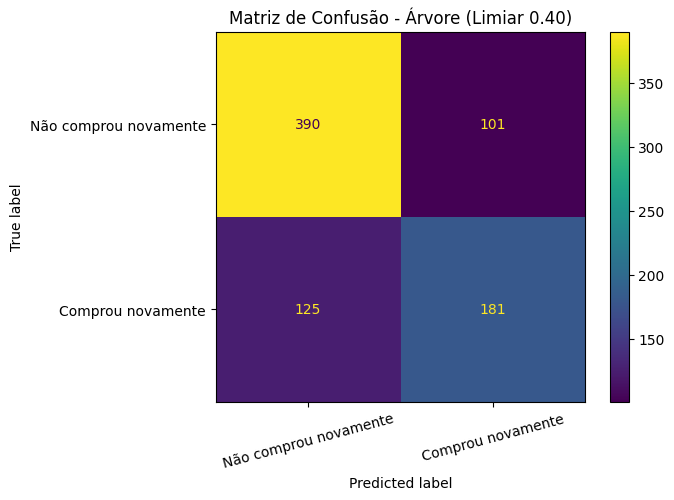

In [70]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Aplicando o limiar de 0.40
previsoes_040 = (probabilidades >= 0.40).astype(int)

# Calculando a matriz de confusão
matriz_040 = confusion_matrix(y_test, previsoes_040)

print("Matriz de confusão - Árvore com limiar 0.40")
print(matriz_040)

# Exibindo o gráfico
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_040,
    display_labels=["Não comprou novamente", "Comprou novamente"]
)

disp.plot(cmap="viridis", values_format="d")
plt.title("Matriz de Confusão - Árvore (Limiar 0.40)")
plt.xticks(rotation=15)
plt.show()


### Interpretação da matriz de confusão

A matriz de confusão mostra que o modelo acertou 459 clientes que não compraram novamente e 118 clientes que compraram novamente.

Foram identificados 32 falsos positivos, ou seja, clientes que o modelo previu que comprariam novamente, mas que não realizaram uma nova compra.

Também ocorreram 188 falsos negativos, que são clientes que realmente compraram novamente, mas foram classificados pelo modelo como clientes que não comprariam.

No contexto do projeto, o falso positivo pode representar o envio de uma ação de marketing para um cliente que não teria comprado novamente. Já o falso negativo representa a perda de uma oportunidade de abordar um cliente que realmente voltou a comprar.

A quantidade de falsos negativos é maior que a quantidade de falsos positivos. Isso ajuda a explicar o recall relativamente baixo da classe "Comprou novamente", de 38,6%.

### Métrica principal escolhida

A métrica principal escolhida para este projeto é o recall da classe "Comprou novamente".

Essa escolha está relacionada ao objetivo de identificar clientes que realmente têm potencial de realizar uma nova compra. Um falso negativo representa um cliente que realmente comprou novamente, mas que não foi identificado pelo modelo. Nesse caso, existe o risco de perder uma oportunidade de direcionar uma ação de relacionamento ou marketing para esse cliente.

Por outro lado, um falso positivo representa um cliente que foi identificado como possível comprador, mas que não realizou uma nova compra. Esse erro pode gerar uma ação de marketing desnecessária.

Neste projeto, considero mais importante reduzir a quantidade de clientes que realmente recomprariam e que não são identificados pelo modelo. Por isso, o recall é a métrica principal, mesmo que isso implique aceitar uma quantidade maior de falsos positivos.

In [71]:
# Avaliando o desempenho do modelo nos dados de treino e de teste
acuracia_treino = modelo.score(X_train, y_train)
acuracia_teste = modelo.score(X_test, y_test)

diferenca = acuracia_treino - acuracia_teste

print("Acurácia no treino:", acuracia_treino)
print("Acurácia no teste:", acuracia_teste)
print("Diferença entre treino e teste:", diferenca)

Acurácia no treino: 0.7214554579673776
Acurácia no teste: 0.7239648682559598
Diferença entre treino e teste: -0.0025094102885822034


### Teste de overfitting

A acurácia do modelo foi de 72,15% nos dados de treino e de 72,40% nos dados de teste. A diferença entre os dois resultados foi de aproximadamente -0,25 ponto percentual.

Como os desempenhos são muito próximos, não foi observado um sinal de overfitting. O modelo não apresentou uma acurácia muito maior no conjunto de treino em relação ao conjunto de teste.

O fato de a acurácia no teste ter ficado ligeiramente acima da acurácia no treino não indica, por si só, um problema de generalização. A diferença é muito pequena e pode ocorrer devido à divisão dos dados.

In [72]:
# Verificando se existem clientes duplicados no conjunto de dados
duplicatas = X.index.duplicated().sum()

print("Quantidade de clientes duplicados:", duplicatas)
print("Quantidade total de clientes:", len(X))

Quantidade de clientes duplicados: 0
Quantidade total de clientes: 3985


### Verificação de possível vazamento de dados

Foi verificada a possibilidade de vazamento de dados no modelo.

Na construção do problema, as características dos clientes foram calculadas utilizando somente as compras realizadas antes da data de corte de novembro de 2011. O alvo foi construído utilizando o período posterior ao corte. Dessa forma, as informações utilizadas nas características não incluem diretamente a resposta que o modelo precisa prever.

Também foi verificada a existência de clientes duplicados no conjunto utilizado para a modelagem. Foram encontrados 0 clientes duplicados entre os 3.985 registros.

A divisão entre treino e teste foi realizada depois da construção das características e do alvo. Como a temporalidade já foi considerada na construção do problema, cada linha representa um cliente com informações do passado e um alvo referente ao futuro. Por isso, a divisão aleatória estratificada entre treino e teste foi utilizada.

Além disso, a transformação da variável `Pais` foi realizada somente após a divisão entre treino e teste, evitando que as categorias do conjunto de teste fossem utilizadas para definir a transformação do conjunto de treinamento.

Com essas verificações, não foi identificado um problema evidente de vazamento de dados ou duplicação de clientes que explique o resultado obtido.

## Conclusão da avaliação do modelo

A avaliação mostrou que a Árvore de Decisão apresentou acurácia de 72,40% no conjunto de teste, enquanto o baseline apresentou 61,61%. Portanto, o modelo apresentou um desempenho superior ao baseline utilizado como referência.

Apesar da acurácia geral de 72,40%, as métricas mostram diferenças entre as duas classes. Para a classe "Comprou novamente", o modelo apresentou precisão de 78,67%, recall de 38,56% e F1-score de 52%. Isso indica que, quando o modelo prevê que um cliente irá recomprar, a previsão apresenta uma precisão relativamente alta, mas o modelo deixa de identificar uma parte considerável dos clientes que realmente recompram.

A matriz de confusão mostrou 118 verdadeiros positivos e 188 falsos negativos para a classe "Comprou novamente". Portanto, uma das principais limitações atuais do modelo é a quantidade de clientes que realmente recompraram, mas não foram identificados pelo modelo.

O recall foi escolhido como métrica principal porque, neste projeto, é importante identificar uma parcela maior dos clientes que realmente voltarão a comprar. Um falso negativo pode representar uma oportunidade de relacionamento ou marketing que não foi identificada.

Na análise de overfitting, a acurácia foi de 72,15% no treino e 72,40% no teste, uma diferença de aproximadamente -0,25 ponto percentual. A proximidade dos resultados não indica um sinal evidente de overfitting.

Também foram realizadas verificações relacionadas a possíveis problemas de vazamento de dados e duplicação. Não foram encontrados clientes duplicados entre os 3.985 registros utilizados na modelagem. A construção das características utilizou informações anteriores à data de corte, enquanto o alvo foi construído a partir do período posterior.

Como próximo passo, será necessário continuar a avaliação do modelo, analisar a matriz de confusão e as métricas com maior profundidade e avaliar possíveis melhorias nas características e no modelo antes da apresentação da AP2.

## ATIVIDADE 13 — Experimento com rede neural

Nesta etapa, será treinada uma rede neural simples (`MLPClassifier`) para prever se um cliente realizará uma nova compra. A comparação será feita com a Árvore de Decisão de profundidade 5 e com o baseline já utilizados neste notebook. Serão mantidos os mesmos conjuntos de treino e teste (`X_train`, `X_test`, `y_train` e `y_test`), a mesma semente usada na divisão e as mesmas métricas.

A métrica principal do projeto continua sendo o **recall da classe “Comprou novamente”**, pois queremos avaliar quantos clientes que realmente voltaram a comprar são identificados.

### Padronização e arquitetura da rede

A rede neural é sensível à escala das variáveis numéricas. Por isso, `StandardScaler` será aplicado dentro de um `Pipeline`: o scaler aprende os parâmetros somente com os dados de treino e aplica a transformação ao teste sem ajustar-se a ele.

Arquitetura inicial escolhida: duas camadas ocultas com 16 e 8 neurônios; ativação ReLU; saída de classificação binária; até 500 épocas (`max_iter=500`). O treinamento também usa parada antecipada (`early_stopping=True`) para interromper o ajuste quando o desempenho de validação deixa de melhorar. O número efetivo de iterações será registrado após o treinamento.

In [73]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.exceptions import ConvergenceWarning
import warnings

# A padronização fica dentro do Pipeline para evitar vazamento de informação.
# O scaler é ajustado apenas em X_train e depois aplicado em X_test.
rede_neural = Pipeline([
    ("padronizacao", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        max_iter=500,
        random_state=42,
        early_stopping=True,
        n_iter_no_change=20
    ))
])

# Captura um possível aviso de convergência para registrá-lo na análise.
with warnings.catch_warnings(record=True) as avisos_treinamento:
    warnings.simplefilter("always", ConvergenceWarning)
    rede_neural.fit(X_train, y_train)

print("Rede neural treinada.")
print("Arquitetura: 16 e 8 neurônios nas camadas ocultas; ativação ReLU.")
print("Iterações realizadas:", rede_neural.named_steps["mlp"].n_iter_)

avisos_convergencia = [aviso for aviso in avisos_treinamento if issubclass(aviso.category, ConvergenceWarning)]
if avisos_convergencia:
    print("Aviso de convergência:")
    for aviso in avisos_convergencia:
        print(str(aviso.message))
else:
    print("Nenhum ConvergenceWarning foi emitido durante o treinamento.")


Rede neural treinada.
Arquitetura: 16 e 8 neurônios nas camadas ocultas; ativação ReLU.
Iterações realizadas: 61
Nenhum ConvergenceWarning foi emitido durante o treinamento.


In [37]:
# Previsões nos mesmos conjuntos usados para avaliar a Árvore de Decisão
pred_rede_treino = rede_neural.predict(X_train)
pred_rede_teste = rede_neural.predict(X_test)

# Métricas de treino e teste para observar a generalização da rede
metricas_rede = pd.DataFrame([
    {
        "Conjunto": "Treino",
        "Acurácia": accuracy_score(y_train, pred_rede_treino),
        "Precisão (classe 1)": precision_score(y_train, pred_rede_treino, zero_division=0),
        "Recall (classe 1)": recall_score(y_train, pred_rede_treino, zero_division=0),
        "F1 (classe 1)": f1_score(y_train, pred_rede_treino, zero_division=0)
    },
    {
        "Conjunto": "Teste",
        "Acurácia": accuracy_score(y_test, pred_rede_teste),
        "Precisão (classe 1)": precision_score(y_test, pred_rede_teste, zero_division=0),
        "Recall (classe 1)": recall_score(y_test, pred_rede_teste, zero_division=0),
        "F1 (classe 1)": f1_score(y_test, pred_rede_teste, zero_division=0)
    }
])

print(metricas_rede.round(4).to_string(index=False))
print("\nRelatório da rede neural no teste:")
print(classification_report(
    y_test,
    pred_rede_teste,
    labels=[0, 1],
    target_names=["Não comprou novamente", "Comprou novamente"],
    zero_division=0
))


Conjunto  Acurácia  Precisão (classe 1)  Recall (classe 1)  F1 (classe 1)
  Treino    0.7168               0.7149             0.4363         0.5419
   Teste    0.7340               0.7398             0.4739         0.5777

Relatório da rede neural no teste:
                       precision    recall  f1-score   support

Não comprou novamente       0.73      0.90      0.81       491
    Comprou novamente       0.74      0.47      0.58       306

             accuracy                           0.73       797
            macro avg       0.74      0.68      0.69       797
         weighted avg       0.74      0.73      0.72       797



In [74]:
# Comparação justa no conjunto de teste: baseline, árvore principal e rede neural
comparacao_final = pd.DataFrame([
    {
        "Modelo": "Baseline",
        "Acurácia": accuracy_score(y_test, y_pred_baseline),
        "Precisão (classe 1)": precision_score(y_test, y_pred_baseline, zero_division=0),
        "Recall (classe 1)": recall_score(y_test, y_pred_baseline, zero_division=0),
        "F1 (classe 1)": f1_score(y_test, y_pred_baseline, zero_division=0)
    },
    {
        "Modelo": "Árvore de Decisão (profundidade 5)",
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão (classe 1)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (classe 1)": recall_score(y_test, y_pred, zero_division=0),
        "F1 (classe 1)": f1_score(y_test, y_pred, zero_division=0)
    },
    {
        "Modelo": "Rede neural MLP (16, 8)",
        "Acurácia": accuracy_score(y_test, pred_rede_teste),
        "Precisão (classe 1)": precision_score(y_test, pred_rede_teste, zero_division=0),
        "Recall (classe 1)": recall_score(y_test, pred_rede_teste, zero_division=0),
        "F1 (classe 1)": f1_score(y_test, pred_rede_teste, zero_division=0)
    }
])

print(comparacao_final.round(4).to_string(index=False))


                            Modelo  Acurácia  Precisão (classe 1)  Recall (classe 1)  F1 (classe 1)
                          Baseline    0.6161               0.0000             0.0000         0.0000
Árvore de Decisão (profundidade 5)    0.7240               0.7867             0.3856         0.5175
           Rede neural MLP (16, 8)    0.7340               0.7398             0.4739         0.5777


### Interpretação dos resultados da rede neural

Na execução registrada, a rede neural obteve **73,40% de acurácia**, acima da Árvore de Decisão de profundidade 5 (**72,40%**) e do baseline (**61,61%**). A métrica principal, o recall da classe “Comprou novamente”, foi de **47,39%** na rede neural, contra **38,56%** na árvore. Portanto, neste teste, a rede identificou uma parcela maior dos clientes que realmente voltaram a comprar, embora ainda deixe de identificar mais da metade deles.

A precisão da rede para a classe positiva foi de **73,98%** e o F1-score foi de **0,5777**. Esses valores devem ser lidos em conjunto: o aumento do recall veio acompanhado de uma precisão um pouco menor que a precisão de 78,67% da árvore, mas o F1-score da rede ficou acima do F1 da árvore (aproximadamente 0,5175).

**Hipótese técnica:** a padronização das variáveis numéricas pode ter ajudado o MLP a aprender combinações não lineares entre as características agregadas dos clientes. Como a base possui poucas características por cliente, a diferença não garante que uma rede neural seja sempre superior; o resultado depende da divisão e da configuração escolhida.

**Overfitting:** a acurácia da rede foi de **71,68% no treino** e **73,40% no teste**. O recall foi de **43,63% no treino** e **47,39% no teste**. Como as métricas do teste não ficaram abaixo das métricas de treino, não há sinal evidente de sobreajuste nesta execução. Ainda assim, isso não prova ausência de overfitting em outras divisões ou em dados futuros.

**Convergência:** nesta execução, a rede terminou em **61 iterações** e não emitiu `ConvergenceWarning`. Foi usada parada antecipada (`early_stopping=True`) com limite de até 500 iterações.


### Decisão sobre o uso da rede neural no SmartShop AI

**Decisão: manter a rede neural como candidata para o projeto final, sem descartar a Árvore de Decisão.** Nesta execução, o MLP melhorou a métrica principal: o recall passou de 38,56% na árvore para 47,39% na rede neural, um aumento de 8,83 pontos percentuais. A acurácia também aumentou de 72,40% para 73,40%.

A rede pode ajudar a identificar mais clientes que voltarão a comprar, mas é mais difícil de interpretar do que a árvore. Por isso, a decisão é comparar os dois modelos novamente antes da entrega final e considerar o custo de falsos positivos e falsos negativos. Os resultados atuais vêm de uma única divisão de treino e teste; não são garantia de que a rede terá sempre o melhor desempenho.


### Dificuldades técnicas e limitações

Uma dificuldade importante foi garantir que o notebook pudesse ser executado de cima para baixo. Algumas células originais consultavam `y_train` e `y_test` antes da célula que criava esses conjuntos; a ordem foi ajustada para que a divisão ocorra antes das análises e do baseline.

Para a rede neural, foi necessário padronizar as características numéricas. O `StandardScaler` foi colocado dentro de um `Pipeline`, para ser ajustado apenas com os dados de treino. Nesta execução, o treinamento terminou em 61 iterações e não apresentou aviso de convergência.

A principal limitação é que a comparação utiliza uma única divisão treino/teste e uma configuração inicial de rede neural. Os resultados devem ser interpretados como um experimento, não como prova definitiva de superioridade. O recall da rede ainda ficou abaixo de 50%, portanto ainda há muitos clientes que recompram e não são identificados.
